# Homework data: basic feasibility review

This notebook checks whether the one-minute Binance futures data is sufficient for the cross-asset leadership project. It inventories the files, applies the required `carryover == 0` filter, joins quote and trade data, and produces simple plots. The plots use January–June 2025 so the notebook runs quickly; the inventory covers the full archive.

In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 50)
plt.style.use("seaborn-v0_8-whitegrid")

In [3]:
def find_repo_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "data/binance/futures/latest").exists():
            return candidate
    raise FileNotFoundError("Could not find data/binance/futures/latest.")

REPO_ROOT = find_repo_root(Path.cwd().resolve())
DATA_ROOT = REPO_ROOT / "data/binance/futures/latest"
SYMBOLS = ["BTCUSDT", "ETHUSDT", "SOLUSDT", "XRPUSDT", "DOGEUSDT"]
START_DATE, END_DATE = "20250101", "20250630"
DATA_ROOT

PosixPath('/Users/hankrugg/Fordham/Fall26/Crypto/Project/notset-algo-trading-project/data/binance/futures/latest')

## Data available and how we will use it

The archive contains three complementary one-minute datasets. The primary signal can be completed with level-one and trade data. Book data is useful for liquidity controls and the optional execution extension.

### `level1_1min`: prices, quotes, and top-of-book conditions

| Field group | Included variables | Planned use |
|---|---|---|
| Time and quality | `ts_end`, `bin_id`, `carryover`, `ramp_up` | Align assets by minute and exclude carried or incomplete observations. |
| Mid-price | `open_mid`, `first_mid`, `close_mid`, `min_mid`, `max_mid` | Calculate returns, rolling betas, residual returns, volatility, and prediction targets. |
| Best quotes | `close_bid`, `close_ask`, `max_bid`, `min_ask` | Calculate spreads and approximate entry and exit prices. |
| Quote sizes | `close_bid_size`, `close_ask_size`, `mean_bid_size`, `mean_ask_size` | Construct top-of-book imbalance and measure displayed buying or selling liquidity. |
| Spread statistics | `median_spread`, `mean_spread`, `min_spread`, `max_spread` | Control for liquidity and estimate whether predicted returns can cover the spread. |
| Activity and volatility | `tick_count`, `l3_updates`, `tick_volatility`, bid/ask return fields | Measure market activity and volatility regimes. |

**Main role:** construct returns and residuals, estimate each follower's BTC beta, create liquidity features, and approximate trading costs.

### `trade_1min`: executed trades and order flow

| Field group | Included variables | Planned use |
|---|---|---|
| Time and quality | `ts_end`, `bin_id`, `carryover`, `ramp_up` | Align trades with level-one prices and remove invalid observations. |
| Trade counts | `trade_count`, buy/sell counts, taker counts | Measure activity and determine whether pressure comes from many trades or a few prints. |
| Trade prices | `open_price`, `first_price`, `close_price`, `min_price`, `max_price`, `median_price` | Compare trades with quoted mids and check for bid-ask bounce. |
| Volume | `volume`, `buy_volume`, `sell_volume` | Construct signed volume and trade imbalance: `(buy_volume - sell_volume) / (buy_volume + sell_volume)`. |
| VWAP | `vwap`, `buy_vwap`, `sell_vwap` | Describe where trading occurred and compare execution prices with observed volume-weighted prices. |
| Trade volatility | `trade_volatility` | Add a short-horizon risk and activity control. |

**Main role:** provide BTC price-pressure and order-flow features used to predict future raw and residual returns in ETH, SOL, XRP, and DOGE.

### `book_1min`: market depth and executable liquidity

| Field group | Included variables | Planned use |
|---|---|---|
| Time and quality | `ts_end`, `ts_book`, `bin_id`, `carryover`, `ramp_up` | Align snapshots with the other tables and exclude carried observations. |
| Best book | `bid_price`, `ask_price`, `bid_size`, `ask_size` | Confirm top-of-book liquidity and construct snapshot book imbalance. |
| Depth by price distance | Bid/ask fill sizes at 1, 3, 10, 30, and 100 bps | Measure how much quantity could be executed within a chosen distance of the best quote. |
| Quantity-based VWAP | Fill sizes and VWAPs for fixed coin quantities | Estimate the price of consuming a specified quantity of the book. |
| Dollar-based VWAP | Fill sizes and VWAPs for fixed dollar notionals | Estimate comparable slippage across assets with different prices. |

**Main role:** provide liquidity and slippage controls. It is optional for the basic predictive model but useful for execution timing and realistic transaction costs.

### Core factors derived from these tables

| Factor or target | Source | Purpose |
|---|---|---|
| BTC and follower log returns | Level-one `close_mid` | Estimate relationships and construct directional targets. |
| Rolling BTC beta | BTC and follower returns | Measure each coin's normal sensitivity to BTC. |
| Residual return | Follower return minus fitted BTC component | Measure follower outperformance or underperformance relative to BTC. |
| BTC trade imbalance | BTC buy and sell volume | Primary candidate predictor of delayed follower movement. |
| Follower trade imbalance | Follower buy and sell volume | Determine whether the follower has already begun reacting. |
| Book imbalance | Bid and ask sizes | Measure pressure in displayed liquidity. |
| Spread and depth | Level-one and book data | Estimate costs and control for liquidity-related false lead-lag effects. |
| Volatility and activity | Level-one and trade data | Scale positions and test whether the relationship changes by regime. |

## 1. Full archive inventory

One file represents one symbol-day. This check does not load the full archive into memory.

In [4]:
inventory_rows = []
for table in ["level1_1min", "trade_1min", "book_1min"]:
    for symbol in SYMBOLS:
        files = sorted((DATA_ROOT / table).glob(f"*/{symbol}.*.csv.gz"))
        dates = [path.parent.name for path in files]
        inventory_rows.append({"table": table, "symbol": symbol, "files": len(files),
                               "first_date": min(dates), "last_date": max(dates)})
inventory = pd.DataFrame(inventory_rows)
inventory

,table,symbol,files,first_date,last_date
0,level1_1min,BTCUSDT,1062,20230101,20251130
1,level1_1min,ETHUSDT,1060,20230101,20251130
2,level1_1min,SOLUSDT,1059,20230101,20251130
3,level1_1min,XRPUSDT,1061,20230101,20251130
4,level1_1min,DOGEUSDT,1062,20230101,20251130
5,trade_1min,BTCUSDT,1062,20230101,20251130
6,trade_1min,ETHUSDT,1062,20230101,20251130
7,trade_1min,SOLUSDT,1062,20230101,20251130
8,trade_1min,XRPUSDT,1062,20230101,20251130
9,trade_1min,DOGEUSDT,1062,20230101,20251130


## 2. Load a six-month sample

We keep prices and spreads from `level1_1min` and buy/sell volume from `trade_1min`. Rows with `carryover != 0` are excluded before joining.

In [5]:
def selected_files(table: str, symbol: str) -> list[Path]:
    files = sorted((DATA_ROOT / table).glob(f"*/{symbol}.*.csv.gz"))
    return [path for path in files if START_DATE <= path.parent.name <= END_DATE]

def load_symbol(symbol: str) -> tuple[pd.DataFrame, dict]:
    level = pd.concat([pd.read_csv(path, usecols=["ts_end", "carryover", "close_mid", "close_bid", "close_ask"])
                       for path in selected_files("level1_1min", symbol)], ignore_index=True)
    trade = pd.concat([pd.read_csv(path, usecols=["ts_end", "carryover", "buy_volume", "sell_volume", "volume"])
                       for path in selected_files("trade_1min", symbol)], ignore_index=True)
    level_valid = level[level["carryover"] == 0].copy()
    trade_valid = trade[trade["carryover"] == 0].copy()
    merged = level_valid.merge(trade_valid.drop(columns="carryover"), on="ts_end",
                               how="inner", validate="one_to_one")
    merged["time"] = pd.to_datetime(merged["ts_end"], unit="ms", utc=True)
    merged["symbol"] = symbol
    merged["spread_bps"] = (merged["close_ask"] - merged["close_bid"]) / merged["close_mid"] * 10_000
    side_volume = merged["buy_volume"] + merged["sell_volume"]
    merged["trade_imbalance"] = np.where(side_volume > 0,
        (merged["buy_volume"] - merged["sell_volume"]) / side_volume, np.nan)
    quality = {"symbol": symbol, "raw_level_rows": len(level),
               "usable_level_rows": len(level_valid), "raw_trade_rows": len(trade),
               "usable_trade_rows": len(trade_valid), "joined_rows": len(merged),
               "median_spread_bps": merged["spread_bps"].median(),
               "non_null_imbalance_pct": merged["trade_imbalance"].notna().mean() * 100}
    return merged, quality

In [6]:
frames, quality_rows = [], []
for symbol in SYMBOLS:
    frame, symbol_quality = load_symbol(symbol)
    frames.append(frame)
    quality_rows.append(symbol_quality)
data = pd.concat(frames, ignore_index=True)
quality = pd.DataFrame(quality_rows)
quality["usable_level_pct"] = quality["usable_level_rows"] / quality["raw_level_rows"] * 100
quality

,symbol,raw_level_rows,usable_level_rows,raw_trade_rows,usable_trade_rows,joined_rows,median_spread_bps,non_null_imbalance_pct,usable_level_pct
0,BTCUSDT,260640,256672,260640,260640,256672,0.010353,100.0,98.477594
1,ETHUSDT,260640,257486,260640,260640,257486,0.040165,100.0,98.789902
2,SOLUSDT,260640,257674,260640,260640,257674,0.658263,100.0,98.862032
3,XRPUSDT,260640,258077,260640,260640,258077,0.434358,100.0,99.016651
4,DOGEUSDT,260640,255780,260640,260640,255780,0.516436,100.0,98.135359


## 3. Basic feasibility plots

These establish coverage and shared market movement. The lag chart is only a naïve diagnostic, not the proposed order-flow/residual-return model.

In [7]:
price = data.pivot(index="time", columns="symbol", values="close_mid").sort_index()
returns = np.log(price).diff()
common_returns = returns.dropna()
correlation = common_returns.corr()
daily_close = price.resample("1D").last().dropna()
normalized_price = daily_close / daily_close.iloc[0] * 100

lag_rows = []
for follower in SYMBOLS[1:]:
    for horizon in [1, 5, 15]:
        aligned = pd.concat([common_returns["BTCUSDT"].rename("btc_now"),
                             common_returns[follower].shift(-horizon).rename("follower_future")], axis=1).dropna()
        lag_rows.append({"follower": follower, "horizon_minutes": horizon,
                         "correlation": aligned["btc_now"].corr(aligned["follower_future"]),
                         "observations": len(aligned)})
lag_correlations = pd.DataFrame(lag_rows)
lag_correlations

,follower,horizon_minutes,correlation,observations
0,ETHUSDT,1,-6.756456e-03,253048
1,ETHUSDT,5,-5.182393e-03,253044
2,ETHUSDT,15,5.935781e-09,253034
3,SOLUSDT,1,-7.102603e-03,253048
4,SOLUSDT,5,-7.016588e-03,253044
5,SOLUSDT,15,3.657997e-03,253034
6,XRPUSDT,1,7.074277e-03,253048
7,XRPUSDT,5,-6.053624e-03,253044
8,XRPUSDT,15,2.591309e-04,253034
9,DOGEUSDT,1,2.139639e-03,253048


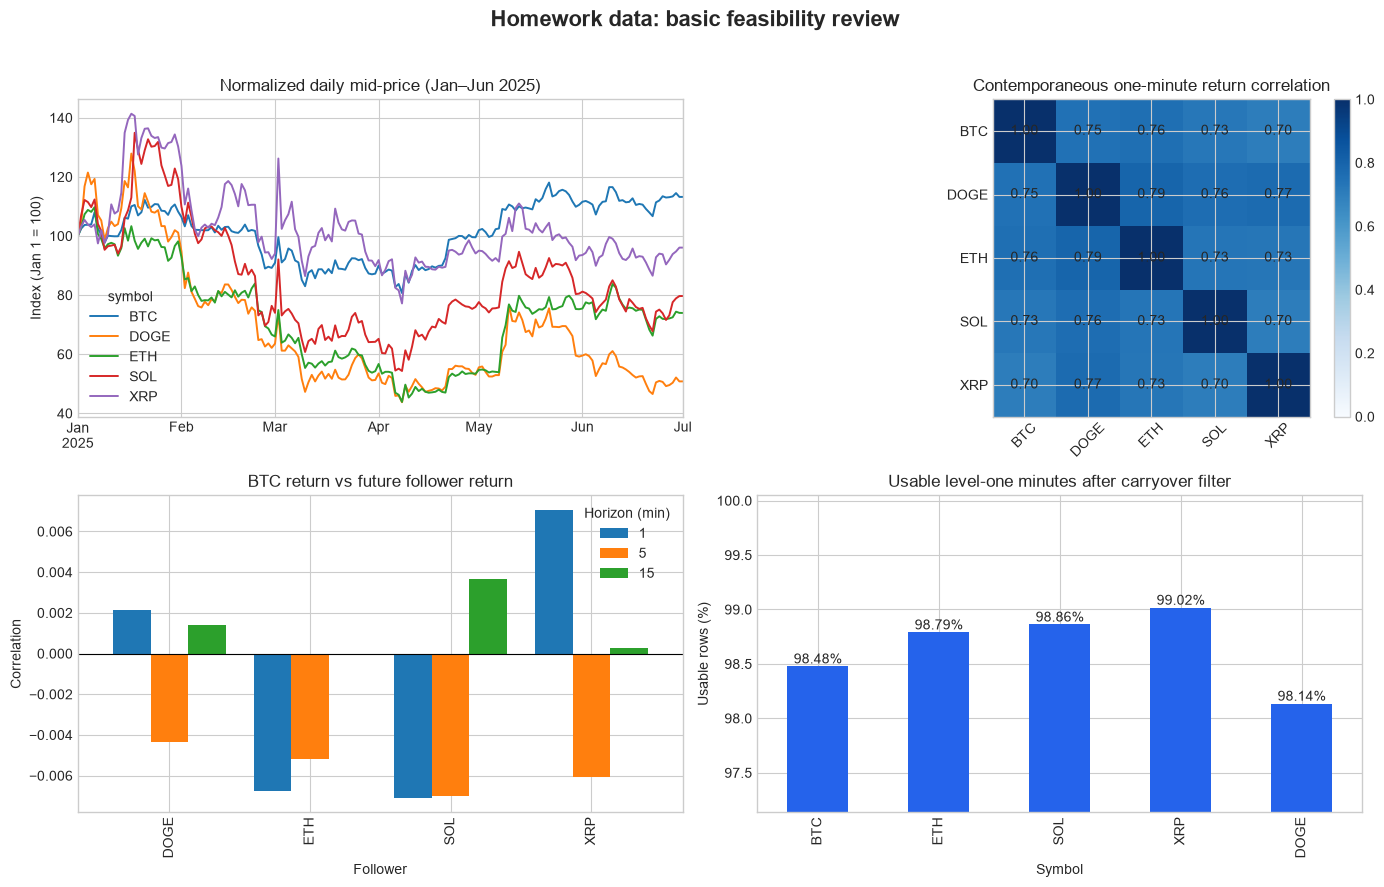

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
normalized_price.rename(columns=lambda x: x.replace("USDT", "")).plot(ax=axes[0, 0], linewidth=1.4)
axes[0, 0].set(title="Normalized daily mid-price (Jan–Jun 2025)", ylabel="Index (Jan 1 = 100)", xlabel="")

labels = [symbol.replace("USDT", "") for symbol in correlation.columns]
heatmap = axes[0, 1].imshow(correlation, vmin=0, vmax=1, cmap="Blues")
axes[0, 1].set_title("Contemporaneous one-minute return correlation")
axes[0, 1].set_xticks(range(len(labels)), labels, rotation=45)
axes[0, 1].set_yticks(range(len(labels)), labels)
for row in range(len(labels)):
    for col in range(len(labels)):
        axes[0, 1].text(col, row, f"{correlation.iloc[row, col]:.2f}", ha="center", va="center")
fig.colorbar(heatmap, ax=axes[0, 1], fraction=0.046, pad=0.04)

lag_plot = lag_correlations.copy()
lag_plot["follower"] = lag_plot["follower"].str.replace("USDT", "")
lag_plot.pivot(index="follower", columns="horizon_minutes", values="correlation").plot(
    kind="bar", ax=axes[1, 0], width=0.8)
axes[1, 0].axhline(0, color="black", linewidth=0.8)
axes[1, 0].set(title="BTC return vs future follower return", ylabel="Correlation", xlabel="Follower")
axes[1, 0].legend(title="Horizon (min)")

usable = quality.set_index("symbol")["usable_level_pct"]
usable.index = usable.index.str.replace("USDT", "")
usable.plot(kind="bar", ax=axes[1, 1], color="#2563eb")
axes[1, 1].set_ylim(max(0, usable.min() - 1), 100.05)
axes[1, 1].set(title="Usable level-one minutes after carryover filter", ylabel="Usable rows (%)", xlabel="Symbol")
for position, value in enumerate(usable):
    axes[1, 1].text(position, value, f"{value:.2f}%", ha="center", va="bottom")

fig.suptitle("Homework data: basic feasibility review", fontsize=16, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

## 4. Feasibility conclusion

The supplied archive is sufficient for the complete minute-level project:

- It covers nearly three years and all five proposed assets.
- The six-month sample alone contains more than one million usable joined minutes.
- More than 98% of level-one rows remain after the carryover filter.
- Strong contemporaneous correlations support beta and residual-return analysis.
- Simple lagged price correlations are small, so the project should test order flow, residual gaps, rolling betas, and out-of-sample forecasts rather than a naïve BTC-return rule.

Tick data can improve the timing analysis later, but it is not required to complete the project.